# Resistance Mutation Checker: E. coli gyrA

**Goal:** check real E. coli strains from NCBI for the two classic fluoroquinolone-resistance positions in the gyrA protein (position 83 and position 87), by comparing each strain against the K-12 MG1655 reference.

**Project dates:** Oct 1 to Oct 10, 2026

In [2]:
from Bio import Entrez,SeqIO

In [3]:
Entrez.email = "your.email@example.com"  # replace with your own email before running

```python
REFERENCE_ID = "NC_000913.3"
import os
reference_file = "sample_data/reference_NC_000913.3.gb"
if not os.path.isfile(reference_file):
    print("Downloading From NCBI...")
    handle = Entrez.efetch(db="nucleotide", id=REFERENCE_ID, rettype="gb", retmode="text")
    reference_record = SeqIO.read(handle, "genbank")
    handle.close()
    SeqIO.write(reference_record,reference_file,"genbank")
    print("Download and saved")
else:
    print("Loading From Disk..")
    reference_record = SeqIO.read(reference_file, "genbank")
    print("Loaded")
print(len(reference_record.features))
```

Abandoned attempt (the cell above): whole-genome download. It hung with gbwithparts and returned a stub with 1 feature with gb.

In [3]:
handle = Entrez.esearch(db="protein", term="gyrA[Gene] AND Escherichia coli K-12[Organism] AND refseq[Filter]", retmax=5)
protein_search = Entrez.read(handle)
handle.close()
print(protein_search["Count"])
print(protein_search["IdList"])

11
['16130166', '447203986', '1933730110', '658505257', '1824722656']


In [4]:
handle = Entrez.efetch(db="protein", id=protein_search["IdList"], rettype="gb", retmode="text")
candidates = list(SeqIO.parse(handle, "genbank"))
handle.close()

for record in candidates:
    print(record.id, "| length:", len(record.seq), "| description:", record.description)

NP_416734.1 | length: 875 | description: DNA gyrase subunit A [Escherichia coli str. K-12 substr. MG1655]
WP_001281242.1 | length: 875 | description: MULTISPECIES: DNA topoisomerase (ATP-hydrolyzing) subunit A [Enterobacteriaceae]
WP_195184464.1 | length: 875 | description: DNA topoisomerase (ATP-hydrolyzing) subunit A [Escherichia coli]
WP_029701249.1 | length: 875 | description: MULTISPECIES: DNA topoisomerase (ATP-hydrolyzing) subunit A [Enterobacteriaceae]
WP_166686339.1 | length: 875 | description: DNA topoisomerase (ATP-hydrolyzing) subunit A [Escherichia coli]


In [5]:
reference_record = candidates[0]
reference_gyra = str(reference_record.seq)

print("ID:", reference_record.id)
print("Length:", len(reference_gyra))
print("Position 83:", reference_gyra[82])
print("Position 87:", reference_gyra[86])

ID: NP_416734.1
Length: 875
Position 83: S
Position 87: D


In [9]:
with open("sample_data/reference_gyrA.txt", "w") as f:
    f.write(reference_gyra)
print("Saved")

Saved


In [2]:
with open("sample_data/reference_gyrA.txt", "r") as f:
    reference_gyra = f.read()

print(len(reference_gyra), reference_gyra[82], reference_gyra[86])

875 S D


## Day 2: Thu Oct 2: Other gyrA variants (rerun on Oct 4)

Searched the protein database for E. coli gyrA (12,651 records on Oct 4) and fetched the first 20. Checked lengths against the 875-amino-acid reference: 15 matched, 4 were different (two partial fragments of 41 and 151, and two of 878), and 1 was the reference itself. Saved the 15 matching records to sample_data/kept_strains.fasta and the 4 others to sample_data/flagged_strains.fasta.

Notes: the search first returned 12,647 records on Oct 2 and 12,651 on Oct 4, so the first 20 changed. I fetched once, saved to files, and now the notebook reads only from those files. Most records were WP_ records, which are shared protein variants, not single strains.

```python
handle = Entrez.esearch(db="protein", term="gyrA[Gene] AND Escherichia coli[Organism]", retmax=20)
strain_search = Entrez.read(handle)
handle.close()
print(strain_search["Count"])
print(strain_search["IdList"])
```

```python
handle = Entrez.efetch(db="protein", id=strain_search["IdList"], rettype="gb", retmode="text")
strain_records = list(SeqIO.parse(handle, "genbank"))
handle.close()
for record in strain_records:
    print(record.id, "|length:", len(record.seq),"|description:", (record.description))
```

```python
kept_records = []
flagged_records = []
for record in strain_records:
    if record.id == "NP_416734.1":
        print(record.id, "-> reference itself, skipped")
    elif len(record.seq) == len(reference_gyra):
        kept_records.append(record)
    else:
        flagged_records.append(record)
print("Kept: ",len(kept_records))
print("Flagged: ",len(flagged_records))
```

```python
SeqIO.write(kept_records, "sample_data/kept_strains.fasta", "fasta")
print("Saved", len(kept_records), "records")
```

In [3]:
kept_records = list(SeqIO.parse("sample_data/kept_strains.fasta", "fasta"))
print(len(kept_records), kept_records[0].id)

15 WP_512009049.1


```python
SeqIO.write(flagged_records, "sample_data/flagged_strains.fasta", "fasta")
print("Saved", len(flagged_records), "flagged records")
```

In [10]:
flagged_records = list(SeqIO.parse("sample_data/flagged_strains.fasta", "fasta"))
print(len(flagged_records), flagged_records[0].id)

4 WP_104919505.1


## Day 3: Fri Oct 3: Position 83 and 87 comparison

Compared the letters at positions 83 and 87 of 15 gyrA variants against the K-12 reference. 10 were wild-type, 1 had S83L only, 1 had D87Y only, and 3 had both S83L and D87N. Results are stored in a list of dictionaries (all_results) for the table.

In [15]:
test_record = kept_records[0]
strain_at_83 = test_record.seq[82]
strain_at_87 = test_record.seq[86]
print(test_record.id)
print("Reference strain at 83rd position: ",reference_gyra[82],"| Strain at 83rd position: ",strain_at_83)
print("Reference strain at 87th position: ",reference_gyra[86],"| Strain at 87nd position: ",strain_at_87)

WP_512009049.1
Reference strain at 83rd position:  S | Strain at 83rd position:  S
Reference strain at 87th position:  D | Strain at 87nd position:  D


In [16]:
all_results = []
for record in kept_records:
    mutations = []
    if record.seq[82] != reference_gyra[82]:
        label = reference_gyra[82] +"83"+ record.seq[82]
        mutations.append(label)
    if record.seq[86] != reference_gyra[86]:
        label = reference_gyra[86] +"87"+ record.seq[86]
        mutations.append(label)
    all_results.append({"id": record.id,"mutations": mutations})
    print(record.id,"->",mutations)
print(len(all_results))

WP_512009049.1 -> []
WP_286109864.1 -> []
WP_167736984.1 -> []
WP_510289066.1 -> []
WP_283799035.1 -> ['S83L', 'D87N']
WP_202837246.1 -> []
WP_506119563.1 -> ['D87Y']
WP_506119039.1 -> ['S83L']
WP_504234688.1 -> []
WP_504237252.1 -> ['S83L', 'D87N']
WP_503380191.1 -> []
WP_503377173.1 -> ['S83L', 'D87N']
YGJ23733.1 -> []
YGJ20273.1 -> []
WP_502722086.1 -> []
15


## Day 4: Sat Oct 4: Results table
Built a table of all 19 records (15 compared + 4 flagged). Result: 10 Wild-Type, 5 Mutant (3 with both S83L and D87N, 1 with S83L only, 1 with D87Y only) and 4 Not compared. Records that were shorter or longer than the reference are labelled "Not compared" instead of "Wild-Type", because a sequence we couldn't check is not the same as one with no change. Saved to outputs/gyra_mutation_report.csv.

In [17]:
test_partial = flagged_records[0]
print(test_partial.id, len(test_partial.seq))
print(test_partial.seq[82])

WP_104919505.1 878
L


In [18]:
for record in flagged_records:
    print(record.id, len(record.seq))

WP_104919505.1 878
YGQ39239.1 41
YGQ39238.1 151
WP_167584261.1 878


In [19]:
test_partial = flagged_records[1]
print(test_partial.id, len(test_partial.seq))
print(test_partial.seq[82])

YGQ39239.1 41


IndexError: index out of range

Tried to read position 83 of the 41-letter fragment YGQ39239.1 and got an IndexError (index out of range), because the sequence has no 83rd letter. This is why fragments and different-length records are labelled "Not compared" and not "Wild-type".

In [20]:
rows = []
for record in kept_records:
    mutations = []
    if record.seq[82] != reference_gyra[82]:
        label = reference_gyra[82] +"83"+record.seq[82]
        mutations.append(label)
    if record.seq[86] != reference_gyra[86]:
        label = reference_gyra[86] +"87"+record.seq[86]
        mutations.append(label)
        
    if len(mutations) > 0:
        status = "Mutant"
    else:
        status = "Wild-Type"
        
    classic = "No"
    for mutation in mutations:
        if mutation == "S83L" or mutation == "D87N":
            classic = "Yes"
            
    if len(mutations) > 0:
        mutations_text = ", ".join(mutations)
    else:
        mutations_text = "None"

    row = {"record_id": record.id,"length": len(record.seq),"at_83": record.seq[82],"at_87": record.seq[86], "mutation_found": mutations_text,
           "classic_mutation": classic,"status": status, "reason": "Same length as reference"}
    rows.append(row)
print(len(rows))
    

15


In [21]:
for record in flagged_records:
    if len(record.seq) < len(reference_gyra):
        reason = "Shorter than reference (partial)"
    else:
        reason = "Longer than reference"
    row = {"record_id": record.id,"length": len(record.seq),"at_83": "N/A","at_87": "N/A", "mutation_found": "Not checked",
           "classic_mutation": "N/A","status": "Not compared", "reason": reason}
    rows.append(row)
print(len(rows))

19


In [22]:
import pandas as pd
df = pd.DataFrame(rows)
df

,record_id,length,at_83,at_87,mutation_found,classic_mutation,status,reason
0,WP_512009049.1,875,S,D,None,No,Wild-Type,Same length as reference
1,WP_286109864.1,875,S,D,None,No,Wild-Type,Same length as reference
2,WP_167736984.1,875,S,D,None,No,Wild-Type,Same length as reference
3,WP_510289066.1,875,S,D,None,No,Wild-Type,Same length as reference
4,WP_283799035.1,875,L,N,"S83L, D87N",Yes,Mutant,Same length as reference
5,WP_202837246.1,875,S,D,None,No,Wild-Type,Same length as reference
6,WP_506119563.1,875,S,Y,D87Y,No,Mutant,Same length as reference
7,WP_506119039.1,875,L,D,S83L,Yes,Mutant,Same length as reference
8,WP_504234688.1,875,S,D,None,No,Wild-Type,Same length as reference
9,WP_504237252.1,875,L,N,"S83L, D87N",Yes,Mutant,Same length as reference


In [23]:
print(df["status"].value_counts())

status
Wild-Type       10
Mutant           5
Not compared     4
Name: count, dtype: int64


In [24]:
df.to_csv("outputs/gyra_mutation_report.csv", index=False)
print("Saved")

Saved


## Day 5: Sun Oct 5: Chart

Made a bar chart of the three statuses (10 Wild-Type, 5 Mutant, 4 Not compared). Not compared has its own bar so the 4 records we couldn't check stay visible. Saved to outputs/mutation_summary.png.

In [1]:
import pandas as pd 
df = pd.read_csv("outputs/gyra_mutation_report.csv")
df

,record_id,length,at_83,at_87,mutation_found,classic_mutation,status,reason
0,WP_512009049.1,875,S,D,NaN,No,Wild-Type,Same length as reference
1,WP_286109864.1,875,S,D,NaN,No,Wild-Type,Same length as reference
2,WP_167736984.1,875,S,D,NaN,No,Wild-Type,Same length as reference
3,WP_510289066.1,875,S,D,NaN,No,Wild-Type,Same length as reference
4,WP_283799035.1,875,L,N,"S83L, D87N",Yes,Mutant,Same length as reference
5,WP_202837246.1,875,S,D,NaN,No,Wild-Type,Same length as reference
6,WP_506119563.1,875,S,Y,D87Y,No,Mutant,Same length as reference
7,WP_506119039.1,875,L,D,S83L,Yes,Mutant,Same length as reference
8,WP_504234688.1,875,S,D,NaN,No,Wild-Type,Same length as reference
9,WP_504237252.1,875,L,N,"S83L, D87N",Yes,Mutant,Same length as reference


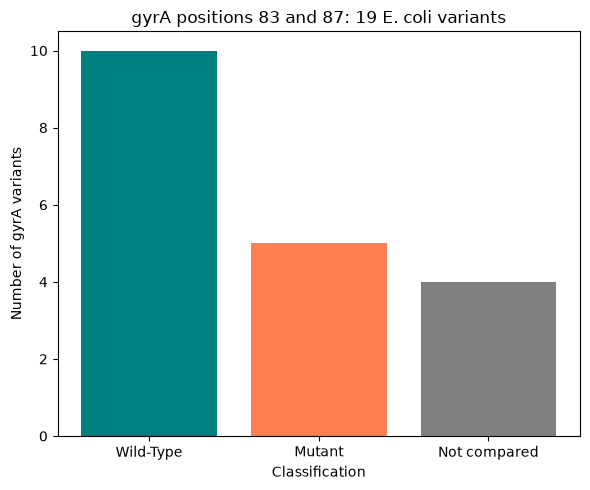

In [6]:
import matplotlib.pyplot as plt
counts = df["status"].value_counts()
plt.figure(figsize=(6,5))
plt.bar(counts.index,counts.values,color=["teal","coral","gray"])
plt.xlabel("Classification")
plt.ylabel("Number of gyrA variants")
plt.title("gyrA positions 83 and 87: 19 E. coli variants")
plt.tight_layout()
plt.savefig("outputs/mutation_summary.png", dpi=300)
plt.show()

## Day 6: Tue Oct 6: Alignment check

Aligned each of the 15 compared variants to the K-12 reference using PairwiseAligner. All 15 lined up in one unbroken stretch (no gaps), so the numbering at positions 83 and 87 is confirmed.

Most alignment scores were below 875, which means those variants differ from the reference at other positions in gyrA too. Wild-Type in my table means no change at 83 or 87, not identical to the reference.

In [4]:
from Bio import Align
aligner = Align.PairwiseAligner()
aligner.mode = "global"
aligner.match_score = +1
aligner.mismatch_score = 0
aligner.open_gap_score = -1
aligner.extend_gap_score = -0.5

In [5]:
for record in kept_records:
    seq_text = str(record.seq)
    best = aligner.align(reference_gyra, seq_text)[0]
    print(record.id,best.score,len(best.aligned[0]))

WP_512009049.1 873.0 1
WP_286109864.1 873.0 1
WP_167736984.1 874.0 1
WP_510289066.1 874.0 1
WP_283799035.1 871.0 1
WP_202837246.1 872.0 1
WP_506119563.1 871.0 1
WP_506119039.1 872.0 1
WP_504234688.1 870.0 1
WP_504237252.1 870.0 1
WP_503380191.1 874.0 1
WP_503377173.1 872.0 1
YGJ23733.1 874.0 1
YGJ20273.1 875.0 1
WP_502722086.1 873.0 1
